# Анализ системы метрик приложения

Вы — продуктовый аналитик приложения Procrastinate Pro+, которое предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

Ваши задачи:
- провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- разобраться в причинах стагнации выручки;
- определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- дать рекомендации отделу маркетинга.


### Данные

В вашем распоряжении есть данные о посещениях приложения, покупках и расходах на маркетинг.
Данные собраны в трёх датасетах.

1. Датасет `ppro_visits.csv` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `ppro_orders.csv` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `ppro_costs.csv` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных

Загрузите данные и получите основную информацию о них. Проведите необходимую предобработку. Основную информацию о данных и предобработке зафиксируйте в кратком промежуточном выводе.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors



In [2]:
# Настройки отображения DataFrame
pd.set_option('display.max_columns', None)  # Отображать все столбцы
pd.set_option('display.expand_frame_repr', False)  # Отключить перенос строк

#Загрузим таблицы в переменные
df_visits = pd.read_csv('data/ppro_visits.csv')
df_orders = pd.read_csv('data/ppro_orders.csv')
df_costs = pd.read_csv('data/ppro_costs.csv')

#Приведем даты в тип datetime и нормализуем для корректной связки и преобразований
df_visits['session_start'] = pd.to_datetime(df_visits['session_start']).dt.normalize()
df_visits['session_end'] = pd.to_datetime(df_visits['session_end']).dt.normalize()
df_orders['event_dt'] = pd.to_datetime(df_orders['event_dt']).dt.normalize()
df_costs['dt'] = pd.to_datetime(df_costs['dt']).dt.normalize()

#Выведем первые строки датафреймов
display(df_visits.head(), df_orders.head(), df_costs.head())

#Выведем информацию о датафреймах
display(df_visits.info(), df_orders.info(), df_costs.info())

,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01,2024-04-01
1,892885906464,India,tv,RocketSuperAds,2024-04-01,2024-04-01
2,517003690029,India,mobile,MediaTornado,2024-04-01,2024-04-01
3,185156659289,India,mobile,MediaTornado,2024-04-01,2024-04-01
4,409503040345,India,mobile,RocketSuperAds,2024-04-01,2024-04-01


,user_id,event_dt,revenue
0,771951256319,2024-04-01,2.99
1,829942381059,2024-04-01,2.99
2,727879856738,2024-04-01,14.99
3,481270888930,2024-04-01,2.99
4,844695029762,2024-04-01,2.99


,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   user_id        161865 non-null  int64         
 1   region         161865 non-null  object        
 2   device         161865 non-null  object        
 3   channel        161865 non-null  object        
 4   session_start  161865 non-null  datetime64[ns]
 5   session_end    161865 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(3)
memory usage: 7.4+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   user_id   33893 non-null  int64         
 1   event_dt  33893 non-null  datetime64[ns]
 2   revenue   33893 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 794.5

None

None

None

Таблица visits содержит 161865 записей, таблица Orders - 33 893 записи, Costs - 976 записей
Во всех таблицах нет пропущенных значений.
Типы данных и названия столбов корретны.
Столбцы с датами и временем имели разрозненный вид, провел нормализацию.

In [3]:
dataframes = {
    'df_visits': df_visits,
    'df_orders': df_orders,
    'df_costs': df_costs
}

for name, df in dataframes.items():
    duplicates_count = df.duplicated().sum()
    print(f'Количество полных дубликатов в {name} = {duplicates_count}')

Количество полных дубликатов в df_visits = 0
Количество полных дубликатов в df_orders = 0
Количество полных дубликатов в df_costs = 0


## Подготовка данных к когортному анализу

Подготовьте данные к когортному анализу с учётом того, что вы будете изучать окупаемость привлечения пользователей за первые 28 дней.

Для каждого пользователя найдите:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраните в новой таблице, например, `profiles`.

Добавьте к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитайте дневной лайфтайм для каждого события или покупки и добавьте в таблицу в виде целого числа. В дальнейшем при проведении когортного анализа используйте информацию о первом источнике привлечения пользователя.

In [ ]:
#Отсортируем датафрейм по времени, чтобы правильно вытащить первый канал
df_visits = df_visits.sort_values(['user_id', 'session_start'])

#Определяем дату первого визита и первый канал для каждого пользователя
profiles = df_visits.groupby('user_id').agg(
    {'session_start': 'min',
     'channel' : 'first'}).reset_index()

#Переименуем столбы
profiles.rename(columns={'session_start':'first_dt' , 'channel': 'first_channel'}, inplace=True)

#Считаем количество пользователей на каждый канал и дату
num_users = profiles.groupby(['first_dt', 'first_channel'])['user_id'].nunique().reset_index()

#Объединяем получившийся датафрейм с таблицой расходов
cac_data = num_users.merge(df_costs, right_on=['dt', 'channel'], left_on = ['first_dt', 'first_channel'], how='left')

#Рассчитываем стоимость привлечения пользователя
cac_data['CAC'] = cac_data['costs'] / cac_data['user_id']

#Создаем итоговый датафрейм по первым визитам и каналам, и с рассчитанным CAC
df_profiles_cac = profiles.merge(cac_data[['first_dt', 'first_channel', 'CAC']], on = ['first_dt', 'first_channel'], how = 'left')

In [ ]:
#Объединяем таблицу с заказами с профилями пользователей
df_orders_lt = df_orders.merge(profiles, on='user_id', how='left')
#Считаем дельту между покупкой и датой первого визита
df_orders_lt['lifetime'] = (df_orders_lt['event_dt'] - df_orders_lt['first_dt']).dt.days

#Объединяем таблицу с визитами с профилями пользователей
df_visits_lt = df_visits.merge(profiles, on='user_id', how='left')
#Считаем дельту между датой визита и датой первого визита
df_visits_lt['lifetime'] = (df_visits_lt['session_start'] - df_visits_lt['first_dt']).dt.days

## Анализ месячной динамики основных метрик продукта

**Задача 1**. Начните анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитайте по всем данным значения DAU, MAU и Stickiness и визуализируйте их. Активными считайте всех пользователей, которые взаимодействовали с приложением.

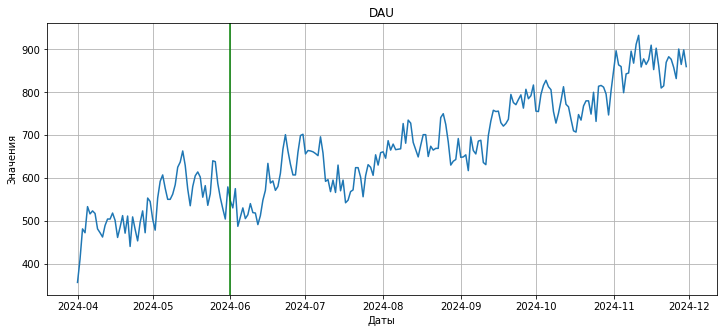

In [6]:

#Создаем столбец с датой
df_visits['date'] = df_visits['session_start'].dt.date

#Cчитаем DAU и визуализируем метрику
dau = df_visits.groupby('date')['user_id'].nunique().reset_index()
plt.subplots(figsize=(12,5))
plt.plot(dau['date'], dau['user_id'])
plt.title('DAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.axvline(x=pd.to_datetime('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

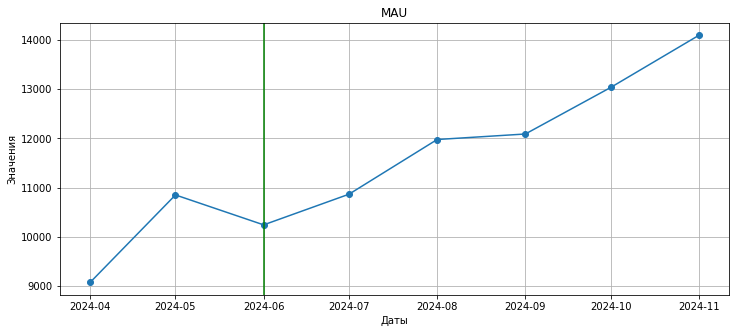

In [7]:
#Создаем столбец с месяцем
df_visits['month'] = df_visits['session_start'].dt.to_period('M').dt.to_timestamp()

#Cчитаем MAU и визуализируем метрику
mau = df_visits.groupby('month')['user_id'].nunique().reset_index()
plt.subplots(figsize=(12,5))
plt.plot(mau['month'], mau['user_id'], marker='o')
plt.title('MAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.axvline(x=pd.to_datetime('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

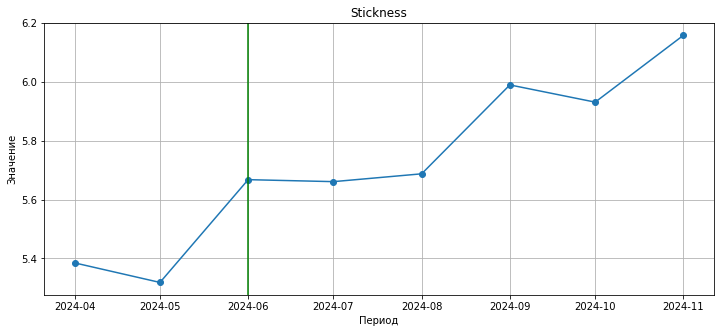

In [8]:
#Округляем до месяца
dau['date'] = pd.to_datetime(dau['date'])
dau['month'] = dau['date'].dt.to_period('M').dt.to_timestamp()

#Считаем среднее количество пользователей на каждый месяц
dau_monthly_average = dau.groupby('month')['user_id'].mean().astype('float64').reset_index()

#Объединяем данные
stickness_table = mau.merge(dau_monthly_average, on = 'month', how = 'left')

#Вычисляем стик и визуализируем
stickness_table['stick'] = (stickness_table['user_id_y'] / stickness_table['user_id_x']) * 100
plt.subplots(figsize=(12,5))
plt.plot(stickness_table['month'], stickness_table['stick'], marker='o')
plt.title('Stickness')
plt.xlabel('Период')
plt.ylabel('Значение')
plt.axvline(x=pd.to_datetime('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

**Задача 2**. В разрезе каждого месяца привлечения новых пользователей рассчитайте:
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

Здесь и далее при расчёте LTV и ROI учитывайте всех привлечённых пользователей когорты.



Визуализируйте метрики и сформулируйте небольшой промежуточный вывод. Сделайте акцент на общей динамике изменения метрик с учётом появления нового контента в начале лета.

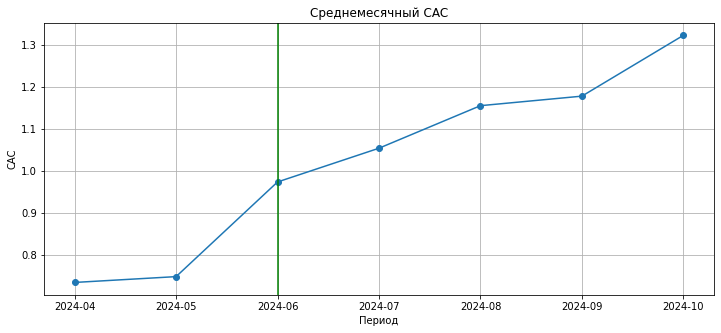

In [9]:
#Округляем до месяца
df_profiles_cac['first_month'] = pd.to_datetime(df_profiles_cac['first_dt']).dt.to_period('M').astype(str)
df_profiles_cac =  df_profiles_cac[df_profiles_cac['first_month'] < '2024-11']

#Считаем средний CAC и визуализируем метрику 
monthly_cac = df_profiles_cac.groupby('first_month')['CAC'].mean().reset_index()
plt.subplots(figsize=(12,5))
plt.plot(monthly_cac['first_month'], monthly_cac['CAC'], marker='o')
plt.title('Среднемесячный CAC')
plt.xlabel('Период')
plt.ylabel('CAC')
plt.axvline(x=('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

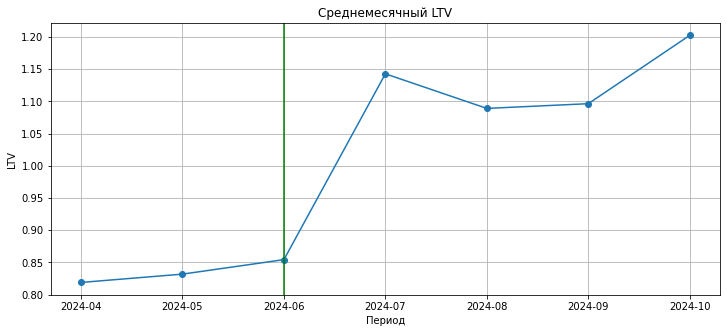

In [10]:
#Ограничиваем заказы период менее 28 дней
df_orders_lt_28d = df_orders_lt[df_orders_lt['lifetime'] <= 27].copy()

df_orders_lt_28d['first_month'] = df_orders_lt_28d['first_dt'].dt.to_period('M').astype(str)

#Ограничим заказы в которых дата заказа позднее октябре 2024, чтобы не учитывать последний месяц в расчете LTV и ROI 
df_orders_lt_28d_corr =  df_orders_lt_28d[df_orders_lt_28d['first_month'] < '2024-11']

#Считаем сумму выручки по каждому месяцу
cohort_revenue = df_orders_lt_28d_corr.groupby('first_month')['revenue'].sum().reset_index()

#Считаем количество пользователей по каждому месяцу
cohort_users = df_profiles_cac.groupby('first_month')['user_id'].nunique().reset_index()

#Создаем таблицу с количеством пользователей и выручкой по каждому месяцу
ltv_monthly = cohort_users.merge(cohort_revenue, on = 'first_month', how = 'left')

#Заполняем пропуски
ltv_monthly['revenue'] = ltv_monthly['revenue'].fillna(0)

#Считаем LTV и визуализируем метрику
ltv_monthly['LTV'] = ltv_monthly['revenue'] / ltv_monthly['user_id']
plt.subplots(figsize=(12,5))
plt.plot(ltv_monthly['first_month'], ltv_monthly['LTV'], marker='o')
plt.title('Среднемесячный LTV')
plt.xlabel('Период')
plt.ylabel('LTV')
plt.axvline(x=('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

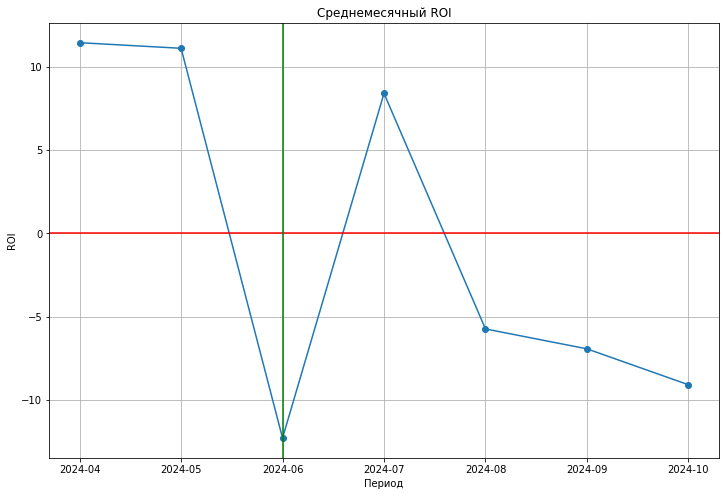

In [11]:
#Создаем общий датафремй с ltv и cac
df_all_metrics = ltv_monthly.merge(monthly_cac, on='first_month', how = 'left')

#Рассчитываем ROI
df_all_metrics['ROI'] = ((df_all_metrics['LTV'] - df_all_metrics['CAC']) / df_all_metrics['CAC']) * 100

#Визуализируем
plt.subplots(figsize=(12,8))
plt.plot(df_all_metrics['first_month'], df_all_metrics['ROI'], marker = 'o')
plt.title('Среднемесячный ROI')
plt.xlabel('Период')
plt.ylabel('ROI')
plt.axhline(y=0, color='red', linestyle='-')
plt.axvline(x=('2024-06'), color='green', linestyle='-')
plt.grid()
plt.show()

В Июне'24 наблюдали тренд на рост метрик DAU и MAU, а также улучшение Sticky-фактора.

При этом начала расти стоимость привлечение пользоателя с менее 0,8 в апреле-мае до 1,32 в октябре-декабре.
Параллельно заметно вырос LTV c примерно 0,85 до введения нового контента до 1,1 - 1,2 в июле-октябре.
Также с начала лета ROI был положительным только в июне, в остальной период значение было отрицательным

## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

**Задача 1**. Определите самые популярные источники привлечения:
- Посчитайте общее число привлечённых пользователей для каждого источника.
- Визуализируйте динамику набора новых пользователей по дням в каждом источнике.
- Рассчитайте и визуализируйте динамику DAU, MAU и Stickiness по источникам привлечения.


In [12]:
#Считаем количество пользователей по каждому каналу привлечения
count_users_total = df_profiles_cac.groupby('first_channel')['user_id'].nunique().reset_index().rename(columns={'user_id': 'users_count'}).sort_values(by='users_count', ascending = False)
display(count_users_total)

,first_channel,users_count
0,FaceBoom,24339
3,TipTop,15413
2,RocketSuperAds,12492
1,MediaTornado,12311


Лидером по количеству привлеченных пользователей был Faceboom(28 401 уникальный пользователь).
TipTop - 18 118 пользователей, RocketSuperAds 14257, MediaTornado 14080.

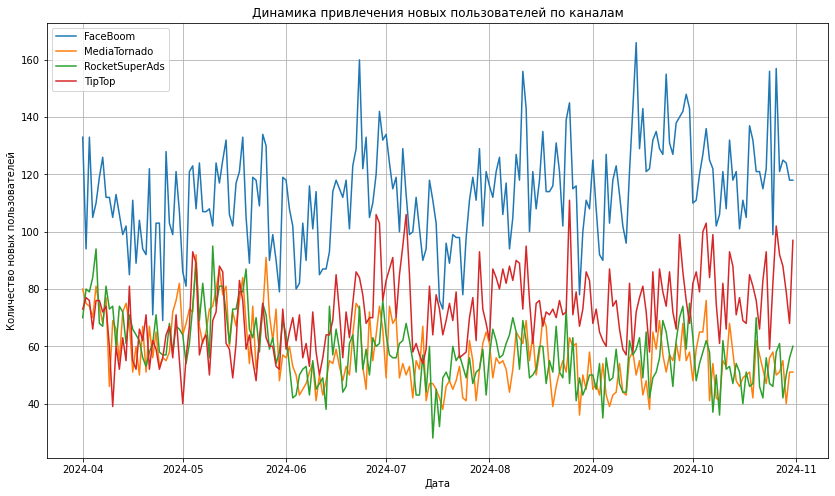

In [13]:
count_users = df_profiles_cac.groupby(['first_channel','first_dt'])['user_id'].nunique().reset_index().rename(columns={'user_id': 'users_count'})
#Строим визуализацию привлечения пользователей по каналам
plt.subplots(figsize=(14,8))
for channel in count_users['first_channel'].unique():
    df_plot = count_users[count_users['first_channel'] == channel]
    plt.plot(df_plot['first_dt'], df_plot['users_count'], label=channel)
plt.legend()
plt.title('Динамика привлечения новых пользователей по каналам')
plt.xlabel('Дата')
plt.ylabel('Количество новых пользователей')
plt.grid()
plt.show()

По недельной динамике привлечения наблюдалось небольшое увеличение количества пользователей по Faceboom c сентября 2024 года.
Tip Top были стабильны.
По RocketSuperAds и MediaTornado было небольшое снижение во второй половине года.

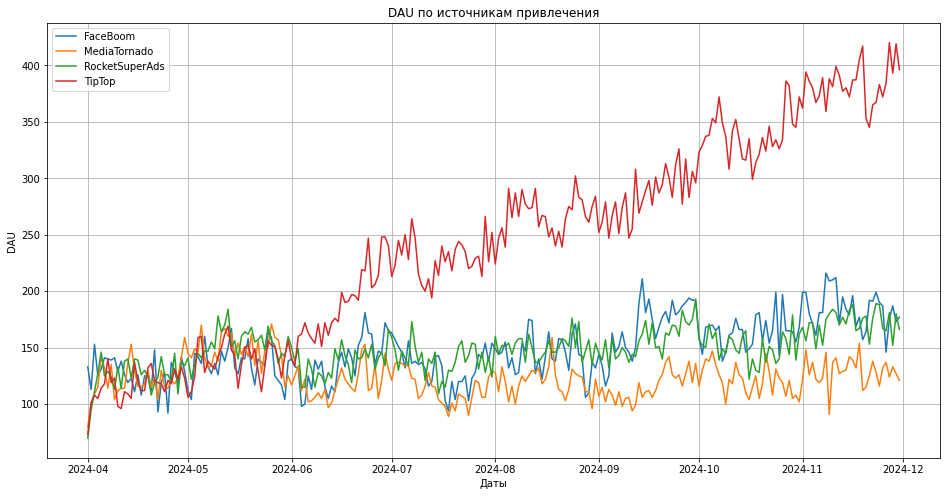

In [14]:
#Создаем столбцы с датой и месяцем для дальнейших действий
df_visits_lt['date'] = df_visits_lt['session_start'].dt.normalize()
df_visits_lt['month'] = df_visits_lt['session_start'].dt.to_period('M').astype(str)

#Считаем количество пользователей для каждого дня и канала
channel_dau = df_visits_lt.groupby(['date', 'first_channel'])['user_id'].nunique().reset_index()

#Строим график
plt.subplots(figsize=(16,8))
for channel in channel_dau['first_channel'].unique():
    df_plot = channel_dau[channel_dau['first_channel'] == channel]
    plt.plot(df_plot['date'], df_plot['user_id'], label=channel)
plt.title('DAU по источникам привлечения')
plt.xlabel('Даты')
plt.ylabel('DAU')
plt.grid()
plt.legend()
plt.show()

Количество активных дневных пользователей по каналу TipTop заметно стало прирастать начиная с июня 2024 года. По другим каналам метрика была стабильна.


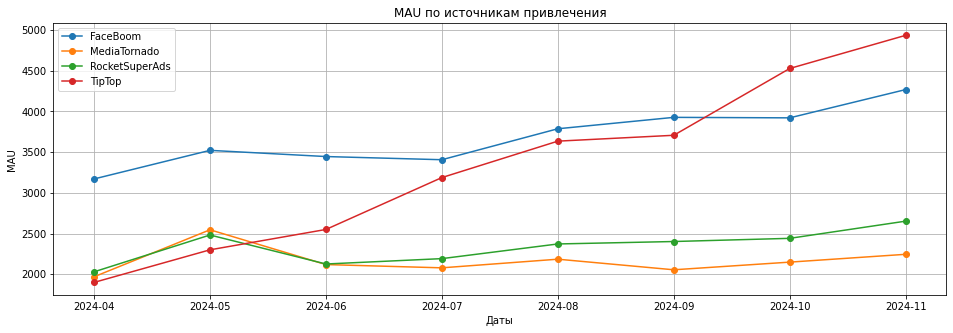

In [15]:
#Считаем количество пользователей для каждого месяца и канала
channel_mau = df_visits_lt.groupby(['month', 'first_channel'])['user_id'].nunique().reset_index()
channel_mau = channel_mau.rename(columns={'user_id': 'mau'})

#Визуализируем
plt.subplots(figsize=(16,5))
for channel in channel_mau['first_channel'].unique():
    df_plot = channel_mau[channel_mau['first_channel'] == channel]
    plt.plot(df_plot['month'], df_plot['mau'], marker='o', label=channel)
plt.title('MAU по источникам привлечения')
plt.xlabel('Даты')
plt.ylabel('MAU')
plt.grid()
plt.legend()
plt.show()

По TipTop начиная с мая 2024 ежемесячно росла метрика MAU, на отчетном периоде метрика выросла более чем в два раза (менее 2000 в апреле, до примерно 5000 в ноябре). В октябре TipTop вышел в лидеры по MAU, опередив Faceboom. По каналу Faceboom рост начался в августе 2024 года и достиг максимума в ноябре 2024.
По остальным каналам были изменения, но не критичные.

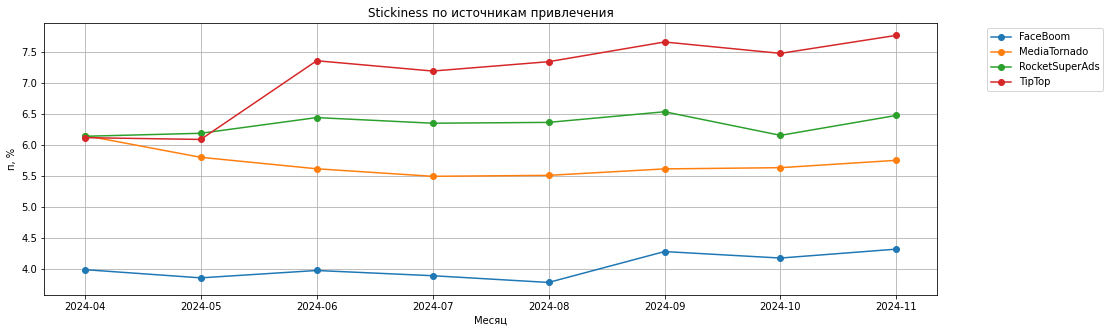

In [16]:
channel_dau['month'] = channel_dau['date'].dt.to_period('M').astype(str)
avg_dau_per_month = channel_dau.groupby(['month', 'first_channel'])['user_id'].mean().reset_index()
avg_dau_per_month = avg_dau_per_month.rename(columns={'user_id': 'avg_dau'})

# Объединяем средний DAU и MAU
stickiness_df = avg_dau_per_month.merge(channel_mau, on=['month', 'first_channel'], how='left')

#Считаем и визуализируем stickiness для каждого канала
stickiness_df['stickiness'] = (stickiness_df['avg_dau'] / stickiness_df['mau']) * 100

plt.subplots(figsize=(16,5))
for channel in stickiness_df['first_channel'].unique():
    df_plot = stickiness_df[stickiness_df['first_channel'] == channel]
    plt.plot(df_plot['month'], df_plot['stickiness'], marker='o', label=channel)

plt.title('Stickiness по источникам привлечения')
plt.xlabel('Месяц')
plt.ylabel('п, %')
plt.grid()
# bbox_to_anchor выносит легенду за пределы графика, чтобы не перекрывать линии
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
plt.show()

Заметные изменения месячного Stickiness были только у TipTop. В канале метрика в июне приросла более чем на 1 п.п относительно мая 2024 года. А в октябре достигла максимума за период на значении свыше 7,5%.
В Faceboom наблюдался рост метрики в сентябре на 0.5 п.п.
В RocketSuperAds и MediaTornado критичных колебаний не было


**Задача 2**. Изучите динамику изменения метрик на 28-й день в разрезе источника. Проведите анализ с выделением недельных когорт по дате привлечения. Рассчитайте и визуализируйте:
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.
- Недельную динамику затрат на маркетинг по каждому источнику привлечения.
- Динамику среднего CAC, значений LTV и ROI.

По результатам проведите анализ рекламных каналов. Дайте общую характеристику каждому рекламному каналу по рассчитанным метрикам. Укажите, какие рекламные каналы не вышли на уровень окупаемости за ожидаемый период, и предположите почему.


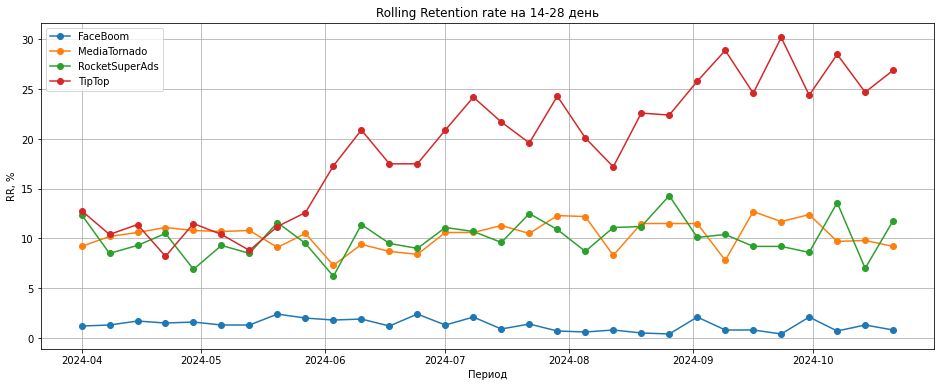

In [17]:
#Ограничим визиты периодом 14-28 дней
df_visits_lt_14d = df_visits_lt[(df_visits_lt['lifetime'] >= 14)&(df_visits_lt['lifetime'] <= 27)].copy()
#Вытащим первую неделю
df_visits_lt_14d['first_week'] = df_visits_lt_14d['first_dt'].dt.to_period('W').dt.start_time

#Посчитаем количество вернувшихся по неделям и каналу
retention_users = df_visits_lt_14d.groupby(['first_week', 'first_channel'])['user_id'].nunique().reset_index()
retention_users.rename(columns={'user_id':'cnt_ret_users'}, inplace=True)
#Округлим до недели всех пользователей
df_visits_lt['first_week'] = df_visits_lt['first_dt'].dt.to_period('W').dt.start_time
#Посчитаем общее количество вернувшихся по неделям и каналу
all_users = df_visits_lt.groupby(['first_week', 'first_channel'])['user_id'].nunique().reset_index()

#Объединим всех и вернувшихся пользователей
retention_table = all_users.merge(retention_users, on=['first_week', 'first_channel'], how='left')
retention_table.rename(columns={'user_id':'all_users'}, inplace=True)
#Заполним пропуски для подстраховки
retention_table['cnt_ret_users'] = retention_table['cnt_ret_users'].fillna(0)

retention_table = retention_table[retention_table['first_week'] < '2024-10-28']

#Считаем Retention Rate
retention_table['rr'] = round(100 * (retention_table['cnt_ret_users'] / retention_table['all_users']),1)

#Визуализируем RR по каналам 
plt.subplots(figsize=(16,6))
for channel in retention_table['first_channel'].unique():
    df_plot = retention_table[retention_table['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['rr'], label=channel, marker = 'o')
plt.title('Rolling Retention rate на 14-28 день')
plt.xlabel('Период')
plt.ylabel('RR, %')
plt.legend()
plt.grid()
plt.show()

Наибольший прирост Rolling Retention был у TipTop. Показатель стал активно расти, начиная с июня и достиг максимальных значений в сентябре-октябре, когда находился в диапазоне 25-30%.
По другим каналам заметных приростов показателей не обнаружено.

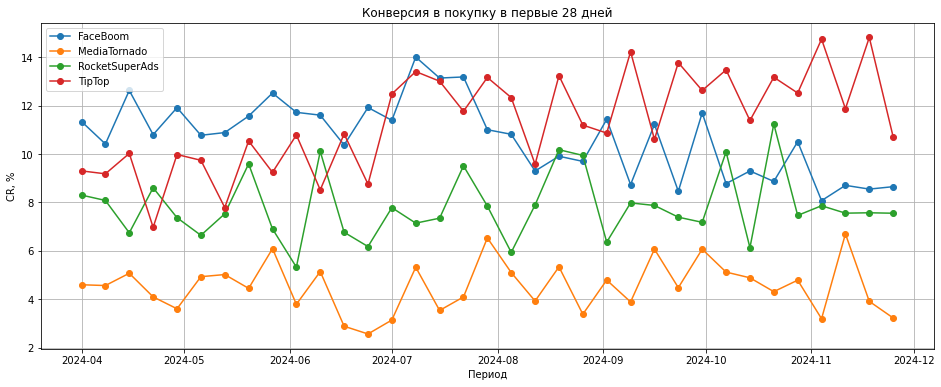

In [18]:
#Вытащим неделю
df_orders_lt_28d['first_week'] = df_orders_lt_28d['first_dt'].dt.to_period('W').dt.start_time
#Посчитаем количество покупателей по неделям и каналу
cnt_orders = df_orders_lt_28d.groupby(['first_week', 'first_channel'])['user_id'].nunique().reset_index()

#Создадим таблицу со всеми пользователями и количеством заказов
cr_table = all_users.merge(cnt_orders, on =['first_week', 'first_channel'], how='left')
cr_table.rename(columns = {'user_id_x':'users', 'user_id_y':'orders'}, inplace=True)

#Заменим пропуски
cr_table['orders'] = cr_table['orders'].fillna(0)

#Посчитаем конверсию
cr_table['cr'] = 100 * (cr_table['orders'] / cr_table['users'])

#Визуализируем динамику конверсии по каналам
plt.subplots(figsize=(16,6))

for channel in cr_table['first_channel'].unique():
    df_plot = cr_table[cr_table['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['cr'], marker='o', label=channel)
plt.title('Конверсия в покупку в первые 28 дней')
plt.xlabel('Период')
plt.ylabel('CR, %')
plt.grid()    
plt.legend()
plt.show()

По конверсии в покупку по каналу TipTop заметен тренд на рост с диапазона 7-11% в апреле-июне до 12-15% в ноябре.
По каналу FaceBoom наблюдали снижение после максимумов на первой недели июля (14%) до 8-10% в ноябре.
По RocketSuperAds и MediaTornado колебания конверсии были в стандартном диапазоне за период.


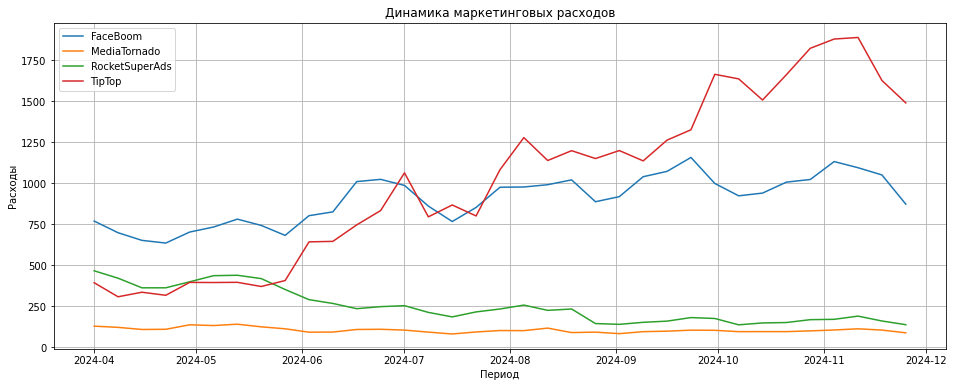

In [19]:
#Вытащим неделю
df_costs['week'] = df_costs['dt'].dt.to_period('W').dt.to_timestamp()

#Посчитаем сумму расходов по неделям и каналам
df_costs_sum = df_costs.groupby(['week', 'channel'])['costs'].sum().reset_index()

#Визуализируем динамику расходов по каналам
plt.subplots(figsize=(16,6))

for channel in df_costs_sum['channel'].unique():
    df_plot = df_costs_sum[df_costs_sum['channel'] == channel]
    plt.plot(df_plot['week'], df_plot['costs'], label=channel)
plt.title('Динамика маркетинговых расходов')
plt.xlabel('Период')
plt.ylabel('Расходы')
plt.grid()    
plt.legend()
plt.show()

Активнее всего росли инвестиции в TipTop, который в июле опередил FaceBoom по бюджетам. В октябре инвестиции превысили 1750 у.е, хотя в апреле-мае бюджеты составляли менее 500 у.е
По FaceBoom тоже был заметен прирост инвестиций в июне-ноябре относительно бюджетов апреля-мая, но менее агрессивный. До внедрения нового контента бюджет на канал был около 750 у.е, затем в некоторые недели превышал 1000-1100 у.е
В RocketSuperAds инвестиции снижались и ноябре сократились более, чем в два раза относительно апреля 2024 года.

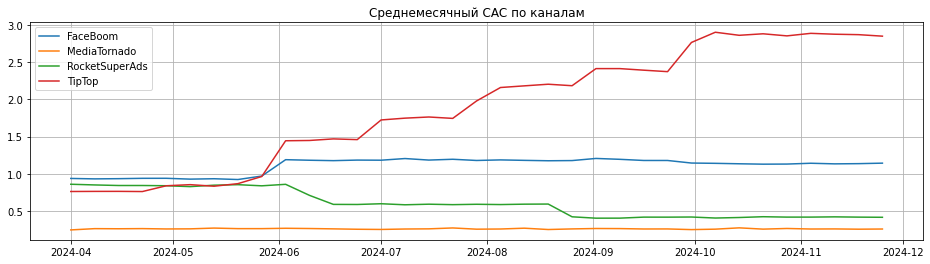

In [20]:
#Объединяем расходы и пользователей по каналам и неделям для расчета CAC
cac_weekly = pd.merge(df_costs_sum, all_users, how='left', left_on=['channel', 'week'], right_on=['first_channel', 'first_week'])
cac_weekly['CAC'] = cac_weekly.costs / cac_weekly.user_id
cac_weekly.rename(columns={'user_id' : 'cnt_users'}, inplace=True)

#Визуализируем с помощью графика CAC по каналам и неделям привлечения
plt.figure(figsize=(16, 4))
for channel in cac_weekly['first_channel'].unique():
    df_plot = cac_weekly[cac_weekly['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['CAC'], label=channel)
plt.title('Среднемесячный CAC по каналам')    
plt.legend()    
plt.grid()    
plt.show()

По каналу TipTop, начиная с июня, каждый месяц начал увеличиваться CAC и октябре-ноябре достиг максимума на уровне около 2,7 у.е
В RocketSuperAds CAC оптимизировался и снизился с 0,8 у.е в апреле-мае до 0,4 у.е сентябре-ноябре.
По FaceBoom CAC вырос до примерно 1,2 у.е в июне и стабилизировался на этом уровне.
По MediaTornado стоимость привлечения была минимальной и стабильной в течение всего периода.

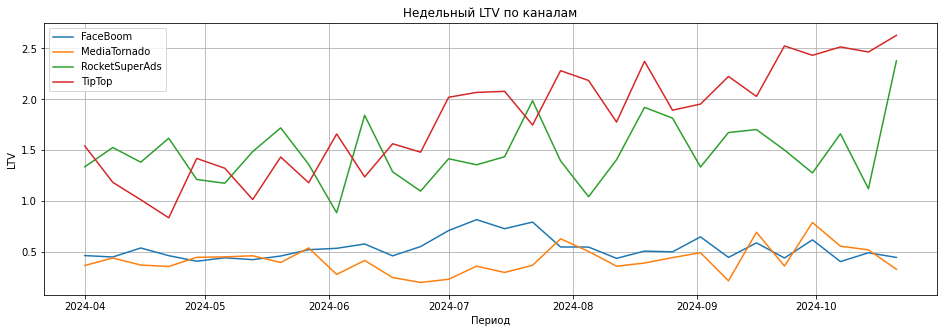

In [21]:


#Считаем общую выручку по каналам и неделям привлечения
df_28d_weekly_revenue = df_orders_lt_28d.groupby(['first_channel', 'first_week'])['revenue'].sum().reset_index()


#Создаем общую таблицу для расчета LTV
ltv_weekly = pd.merge(all_users, df_28d_weekly_revenue, on = ['first_week', 'first_channel'], how = 'left')
ltv_weekly = ltv_weekly[ltv_weekly['first_week'] < '2024-10-28']


#Заполняем пропуски
ltv_weekly['revenue'] = ltv_weekly['revenue'].fillna(0)

#Считаем LTV и визуализируем метрику
ltv_weekly['LTV'] = ltv_weekly['revenue'] / ltv_weekly['user_id']
plt.subplots(figsize=(16,5))
for channel in ltv_weekly['first_channel'].unique():
    df_plot = ltv_weekly[ltv_weekly['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['LTV'], label=channel)
plt.title('Недельный LTV по каналам')
plt.xlabel('Период')
plt.ylabel('LTV')
plt.legend()
plt.grid()
plt.show()

Заметнее других вырос LTV у TipTop и превысил 2,5 в октябре. В апреле-мае показатель не превышал 1,6.
По другим каналам метрика была более стабильна и критичных изменений не замечено

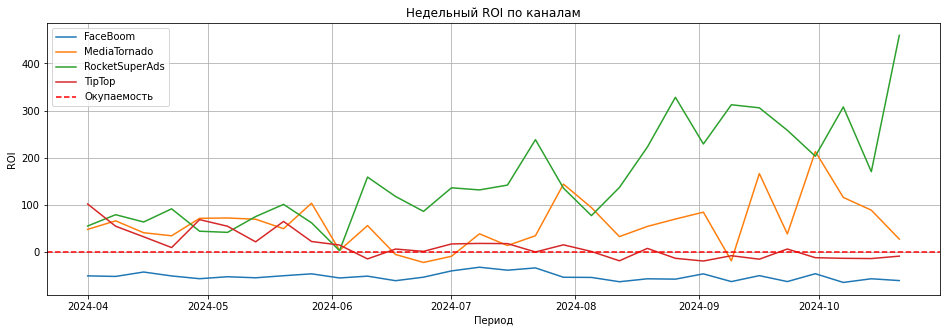

In [22]:
#Объединяем LTV и CAC по неделям и каналам и расчитываем недельныq ROI
roi_weekly = pd.merge(ltv_weekly, cac_weekly, on = ['first_channel', 'first_week'], how='left')
roi_weekly['ROI'] = ((roi_weekly['LTV'] - roi_weekly['CAC']) / roi_weekly['CAC']) * 100

#Визуализируем недельную динамику ROI
plt.subplots(figsize=(16,5))
for channel in roi_weekly['first_channel'].unique():
    df_plot = roi_weekly[roi_weekly['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['ROI'], label=channel)
plt.title('Недельный ROI по каналам')
plt.xlabel('Период')
plt.ylabel('ROI')
plt.axhline(0, color='red', linestyle='--', label='Окупаемость')
plt.legend()
plt.grid()
plt.show()

На этом фоне RocketSuperAds показывали положительный и максимальный ROI по всем каналам в течение всего периода. MediaTornado показывал положительный ROI бОльшую часть времени с небольшими недельными проседаниями.
Tip Top сохранял положительный ROI до июня 2024 года, после чего стал в некоторые недели попадать в отрицательные значения, а с октября 2024 года ушел в стабильный минус.
FaceBoom в течение всего отчетного периода показывал минимальный отрицательный ROI


## Анализ периода окупаемости маркетинговых вложений

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитайте и визуализируйте в виде тепловой карты значения ROI за больший период, например за 8–10 недель.

Разделите данные на недельные когорты по дате привлечения, в качестве интервала наблюдений используйте недели.

Сделайте вывод о том, за какой период окупаются вложения в эти источники.

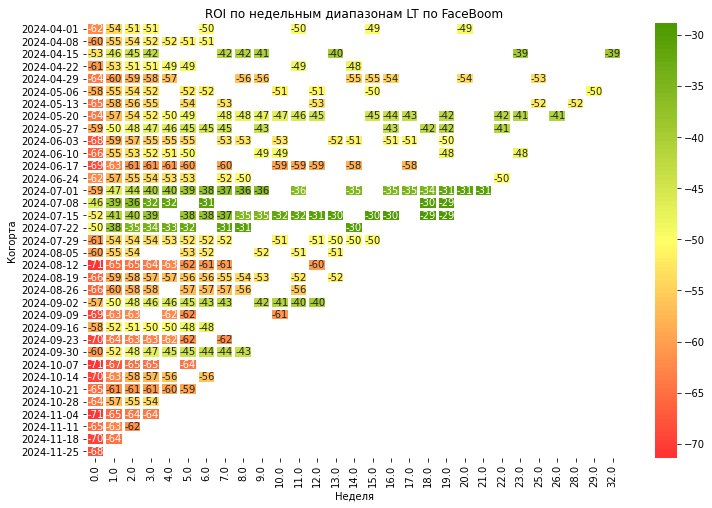

In [23]:
#Оставляем заказы по каналу FaceBoom
df_orders_lt_filtered = df_orders_lt[df_orders_lt['first_channel'] == 'FaceBoom'].copy()

#Рассчитываем недельные периоды
df_orders_lt_filtered['first_week'] = df_orders_lt_filtered['first_dt'].dt.to_period('W').dt.to_timestamp()
df_orders_lt_filtered['order_week'] = df_orders_lt_filtered['event_dt'].dt.to_period('W').dt.to_timestamp()

df_orders_lt_filtered['week_lt'] = (df_orders_lt_filtered['order_week'] - df_orders_lt_filtered['first_week']).dt.days / 7

#Считаем сумму выручку по дате привлечения и недельному интервалу
df_revenue = df_orders_lt_filtered.groupby(['first_week', 'week_lt'])['revenue'].sum().reset_index()
#Сортируем и считаем кумулятивную выручку по неделе привлечения
df_revenue = df_revenue.sort_values(by=['first_week', 'week_lt'])
df_revenue['cum_revenue'] = df_revenue.groupby('first_week')['revenue'].cumsum()

#Оставляем в таблице с недельной CAC только целевой канал и считаем CAC
cac_filtered = cac_weekly[cac_weekly['first_channel'] == 'FaceBoom']
#Фильтруем визиты по целевому каналу
users_filtered = all_users[all_users['first_channel'] == 'FaceBoom']
#Объединяем выручку с пользователями
ltv_filtered = pd.merge(
    df_revenue, 
    users_filtered[['first_week', 'user_id']], # Берем только нужные колонки, чтобы не тащить мусор
    on='first_week', 
    how='left'
)
#Переименуем столбец с количеством пользователей
ltv_filtered = ltv_filtered.rename(columns={'user_id': 'cohort_size'})

#К результату пришиваем CAC (cac_filtered)
ltv_filtered = pd.merge(
    ltv_filtered, 
    cac_filtered[['first_week', 'CAC']], 
    on='first_week', 
    how='left'
)


# Заполняем пропуски
ltv_filtered['cum_revenue'] = ltv_filtered['cum_revenue'].fillna(0)

# Считаем LTV и ROI
ltv_filtered['LTV'] = ltv_filtered['cum_revenue'] / ltv_filtered['cohort_size']
ltv_filtered['ROI'] = (ltv_filtered['LTV'] - ltv_filtered['CAC'])/ltv_filtered['CAC'] * 100


#Считаем средний ROI по когорте и недельному интервалу
df_grouped_roi = ltv_filtered.groupby(['week_lt','first_week'])['ROI'].mean().reset_index()
#Создаем сводную таблицу по ROI в пересчете на когорты и недельные интервалы LT
df_pivot = df_grouped_roi.pivot(index='first_week', columns='week_lt', values='ROI')
df_pivot[df_pivot == 0] = float('nan')
df_pivot.index = df_pivot.index.strftime('%Y-%m-%d')

#Создаем тепловую карту
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)
plt.figure(figsize=(12, 8))
sns.heatmap(df_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0f',
           linewidths=2,
           annot_kws={'size':10})
plt.title('ROI по недельным диапазонам LT по FaceBoom')
plt.xlabel('Неделя')
plt.ylabel('Когорта')
plt.show()

По каналу Faceboom по всем когортам, даже на более длительном периоде положительный ROI не достигается

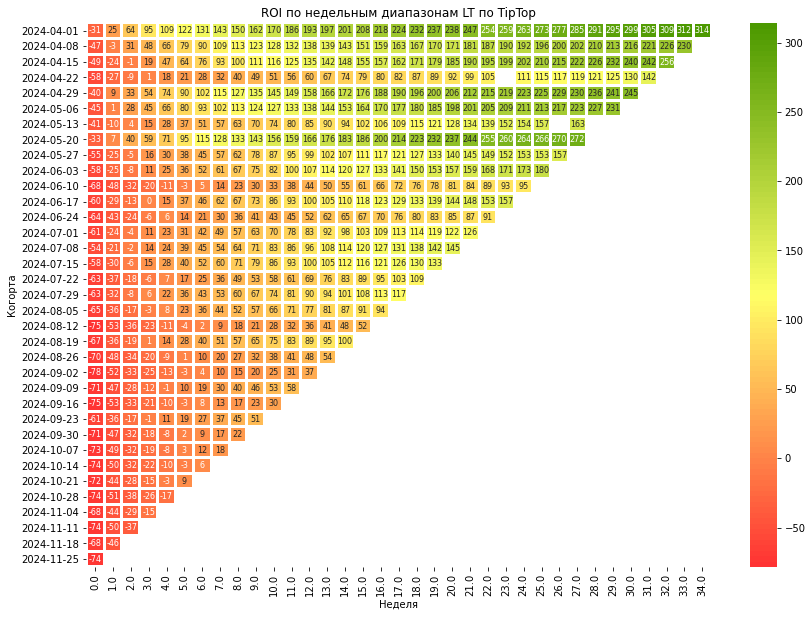

In [24]:
#Оставляем заказы по каналу TipTop
df_orders_lt_filtered = df_orders_lt[df_orders_lt['first_channel'] == 'TipTop'].copy()

#Рассчитываем недельные периоды
df_orders_lt_filtered['first_week'] = df_orders_lt_filtered['first_dt'].dt.to_period('W').dt.to_timestamp()
df_orders_lt_filtered['order_week'] = df_orders_lt_filtered['event_dt'].dt.to_period('W').dt.to_timestamp()

df_orders_lt_filtered['week_lt'] = (df_orders_lt_filtered['order_week'] - df_orders_lt_filtered['first_week']).dt.days / 7

#Считаем сумму выручку по дате привлечения и недельному интервалу
df_revenue = df_orders_lt_filtered.groupby(['first_week', 'week_lt'])['revenue'].sum().reset_index()
#Сортируем и считаем кумулятивную выручку по неделе привлечения
df_revenue = df_revenue.sort_values(by=['first_week', 'week_lt'])
df_revenue['cum_revenue'] = df_revenue.groupby('first_week')['revenue'].cumsum()

#Оставляем в таблице с недельной CAC только целевой канал и считаем CAC
cac_filtered = cac_weekly[cac_weekly['first_channel'] == 'TipTop']
#Фильтруем визиты по целевому каналу
users_filtered = all_users[all_users['first_channel'] == 'TipTop']
#Объединяем выручку с пользователями
ltv_filtered = pd.merge(
    df_revenue, 
    users_filtered[['first_week', 'user_id']], # Берем только нужные колонки, чтобы не тащить мусор
    on='first_week', 
    how='left'
)
#Переименуем столбец с количеством пользователей
ltv_filtered = ltv_filtered.rename(columns={'user_id': 'cohort_size'})

#К результату пришиваем CAC (cac_filtered)
ltv_filtered = pd.merge(
    ltv_filtered, 
    cac_filtered[['first_week', 'CAC']], 
    on='first_week', 
    how='left'
)


# Заполняем пропуски
ltv_filtered['cum_revenue'] = ltv_filtered['cum_revenue'].fillna(0)

# Считаем LTV и ROI
ltv_filtered['LTV'] = ltv_filtered['cum_revenue'] / ltv_filtered['cohort_size']
ltv_filtered['ROI'] = (ltv_filtered['LTV'] - ltv_filtered['CAC'])/ltv_filtered['CAC'] * 100


#Считаем средний ROI по когорте и недельному интервалу
df_grouped_roi = ltv_filtered.groupby(['week_lt','first_week'])['ROI'].mean().reset_index()
#Создаем сводную таблицу по ROI в пересчете на когорты и недельные интервалы LT
df_pivot = df_grouped_roi.pivot(index='first_week', columns='week_lt', values='ROI')
df_pivot[df_pivot == 0] = float('nan')
df_pivot.index = df_pivot.index.strftime('%Y-%m-%d')

#Создаем тепловую карту
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)
plt.figure(figsize=(14, 10))
sns.heatmap(df_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0f',
           linewidths=2,
           annot_kws={'size':8})
plt.title('ROI по недельным диапазонам LT по TipTop')
plt.xlabel('Неделя')
plt.ylabel('Когорта')
plt.show()

По каналу Tip Top когорты до запуска изменений начинали выходить в плюс на второй-третьей неделе. После 1 июня стабильно положительный ROI по всем когортам появляется только к 6-ой неделе

## Выводы и рекомендации

Сформулируйте общий вывод. Зафиксируйте основные результаты и инсайты. Например, охарактеризуйте аудиторию продукта, покажите распределение маркетинговых затрат по каналам привлечения, опишите каждый канал привлечения. Делайте акцент на сильных и слабых сторонах. Укажите, какие каналы привлечения не вышли на окупаемость и по каким причинам.

Дайте рекомендации отделу маркетинга: опишите, как повысить эффективность вложений в рекламу.


После запуска нового спортивного контента и изменения маркетинговой стратегии начался заметный рост дневного и месячного количества активной аудитории. Также повысилась вовлеченность. 



Основное влияние на рост пользователей оказывал рост инвестиций в канал TipTop. При этом прирост новой аудитории не коррелировал с ростом бюджета. По данному каналу заметнее других каналов приросли метрики DAU, MAU, StickyFactor и Rolling Retention на 14-28 день. Конверсия канала и LTV росла, но критичный рост стоимости привлечения в канале до максимальных значений нивелировал положительный эффект и начал негативно влиять на ROI в периоде 28 дней. Канал стал окупаться только на 5-6 неделю по большинству когорт

По каналу Faceboom была минимальная возвращаемость, при этом до середины июня в канал были максимальные инвестиции и бюджеты даже росли. Конверсия по каналу снижалась в июле-ноябре, что нивелировали прирост новых пользователей. Faceboom за весь отчетный период показывал отрицательный ROI и генерировал убыток, не окупая вложения даже на более длительных периодах анализа


    
    
Канал RocketSuperAds был лидером по ROI с растущей динамикой показателя, снижающимся CAC и стабильными метриками конверсии в покупку и Retention, при этом инвестиции в канал сокращались

В канал Mediatornado были минимальные инвестиции и минимальная конверсия в покупку. При этом площадка показывала стабильную возвращаемость пользователей и минимальный CAC. ROI бОльшую часть отчетного периода находился на положительном уровне


Рекомендуем пересмотреть стратегию стоимости привления для канала TipTop, т.к рост CAC в канале на фоне растущих бюджетов оказывал существенное влияние на общую эффективность. Для снижения мог можно проанализировать стратегии назначения ставок в рекламном канале или упростить для аудитории возможность приобретения нового типа контента, продумать механики для выполнения целевого действия (скидки за первую покупку контента)

Аудитория канала Faceboom имела минимальную возвращаемость, что имело ключевое влияние на метрику LTV и при текущем CAC приводило к тому, что вложения не окупались. Рекомендуем пересмотреть бюджет на канал, проанализировать качество привлекаемой аудитории по таргетингам и продумать механики финансовых стимуляций (Персональные бонусы и система лояльности) для удержания аудитории в продукте

Рекомендуем наращивать инвестиции в канал RocketSuperAds, т.к площадка показывала максимальную эффективность и выделялся стабильным уровнем конверсии и Rolling Retention.